# Disease Prediction from Medical Data — CodeAlpha (Task 4)

**Objectif :** prédire si une tumeur du sein est **maligne (cancer)** ou **bénigne** à partir de mesures médicales.

**Dataset :** *Breast Cancer Wisconsin (Diagnostic)* — UCI ML Repository (intégré à scikit-learn). 569 patientes, 30 variables numériques.

**Plan du notebook**
1. Chargement et exploration des données
2. Préparation des données
3. Comparaison de 4 modèles (Logistic Regression, SVM, Random Forest, XGBoost)
4. Optimisation des hyperparamètres
5. Évaluation finale sur le jeu de test
6. Importance des variables
7. Sauvegarde du modèle et prédiction sur un nouveau patient

In [ ]:
!pip install -q xgboost

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             RocCurveDisplay, accuracy_score, precision_score,
                             recall_score, f1_score)
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Chargement et exploration des données

In [ ]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

df["diagnosis"] = 1 - df.pop("target")

print("Dimensions :", df.shape)
df.head()

Dimensions : (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [ ]:
df.info()
print("\nValeurs manquantes :", df.isna().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
mean texture,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
mean perimeter,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
mean area,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
mean smoothness,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
mean compactness,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35
mean concavity,569.0,0.09,0.08,0.00,0.03,0.06,0.13,0.43
mean concave points,569.0,0.05,0.04,0.00,0.02,0.03,0.07,0.20
mean symmetry,569.0,0.18,0.03,0.11,0.16,0.18,0.20,0.30
mean fractal dimension,569.0,0.06,0.01,0.05,0.06,0.06,0.07,0.10


diagnosis
Bénin (0)    357
Malin (1)    212
Name: count, dtype: int64

Proportion de cas malins : 37.3%


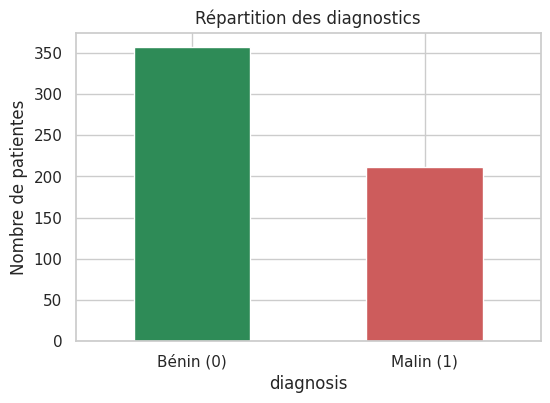

In [ ]:

counts = df["diagnosis"].value_counts().rename({0: "Bénin (0)", 1: "Malin (1)"})
print(counts)
print(f"\nProportion de cas malins : {df['diagnosis'].mean():.1%}")

counts.plot(kind="bar", color=["seagreen", "indianred"], figsize=(6, 4), rot=0)
plt.title("Répartition des diagnostics"); plt.ylabel("Nombre de patientes")
plt.show()


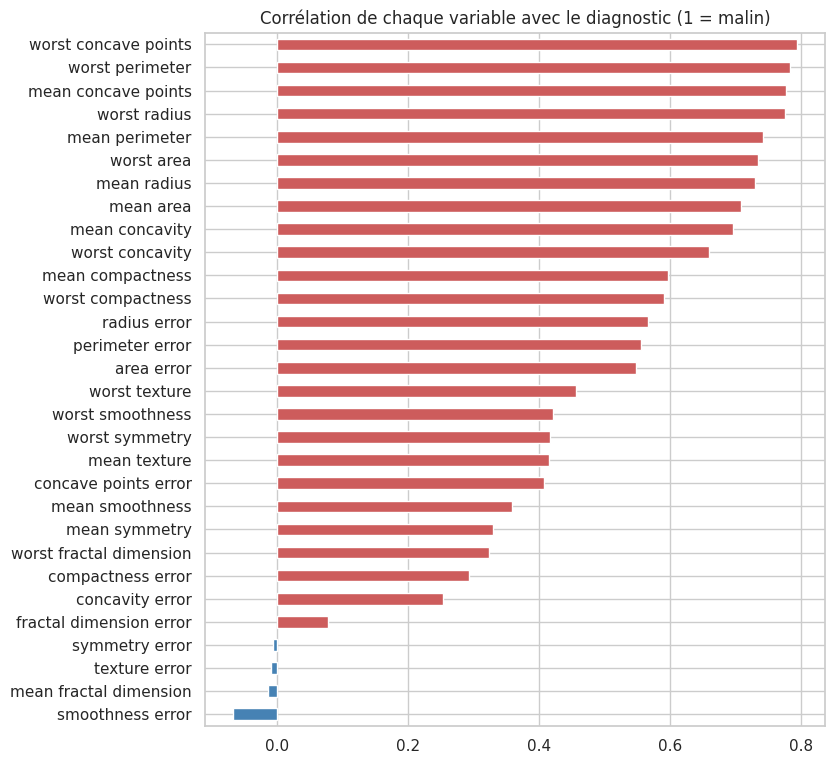

In [ ]:

corr_target = df.corr()["diagnosis"].drop("diagnosis").sort_values(ascending=False)

plt.figure(figsize=(8, 9))
corr_target.plot(kind="barh", color=np.where(corr_target > 0, "indianred", "steelblue"))
plt.title("Corrélation de chaque variable avec le diagnostic (1 = malin)")
plt.gca().invert_yaxis()
plt.show()

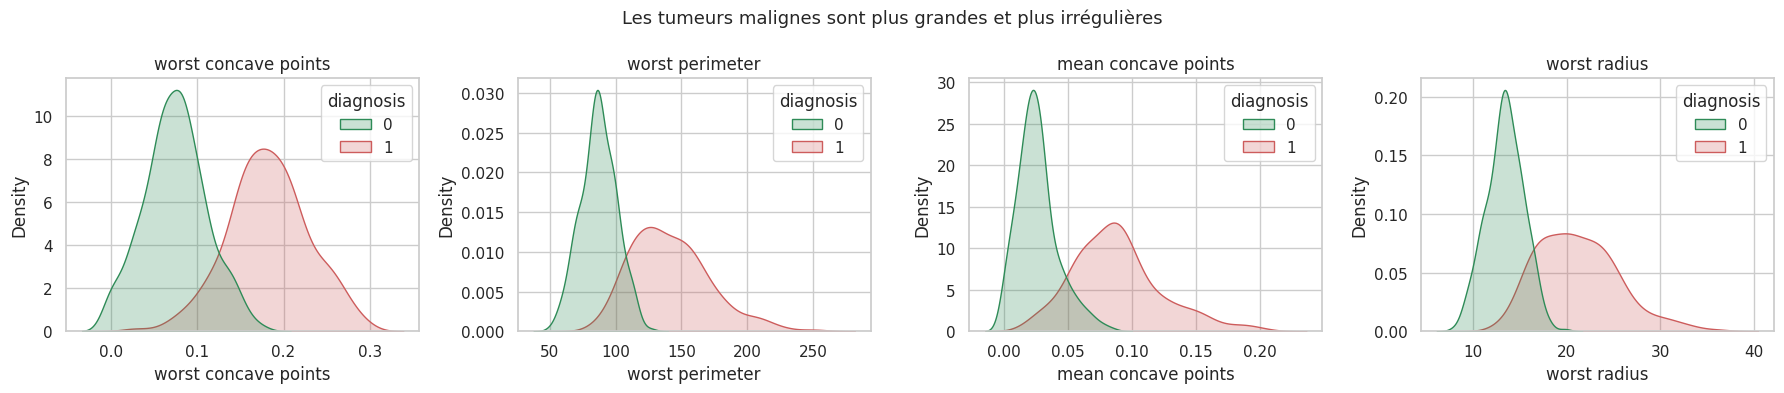

In [ ]:

top_features = corr_target.abs().sort_values(ascending=False).index[:4]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, top_features):
    sns.kdeplot(data=df, x=col, hue="diagnosis", fill=True, common_norm=False,
                palette={0: "seagreen", 1: "indianred"}, ax=ax)
    ax.set_title(col)
plt.suptitle("Les tumeurs malignes sont plus grandes et plus irrégulières", fontsize=13)
plt.tight_layout()
plt.show()

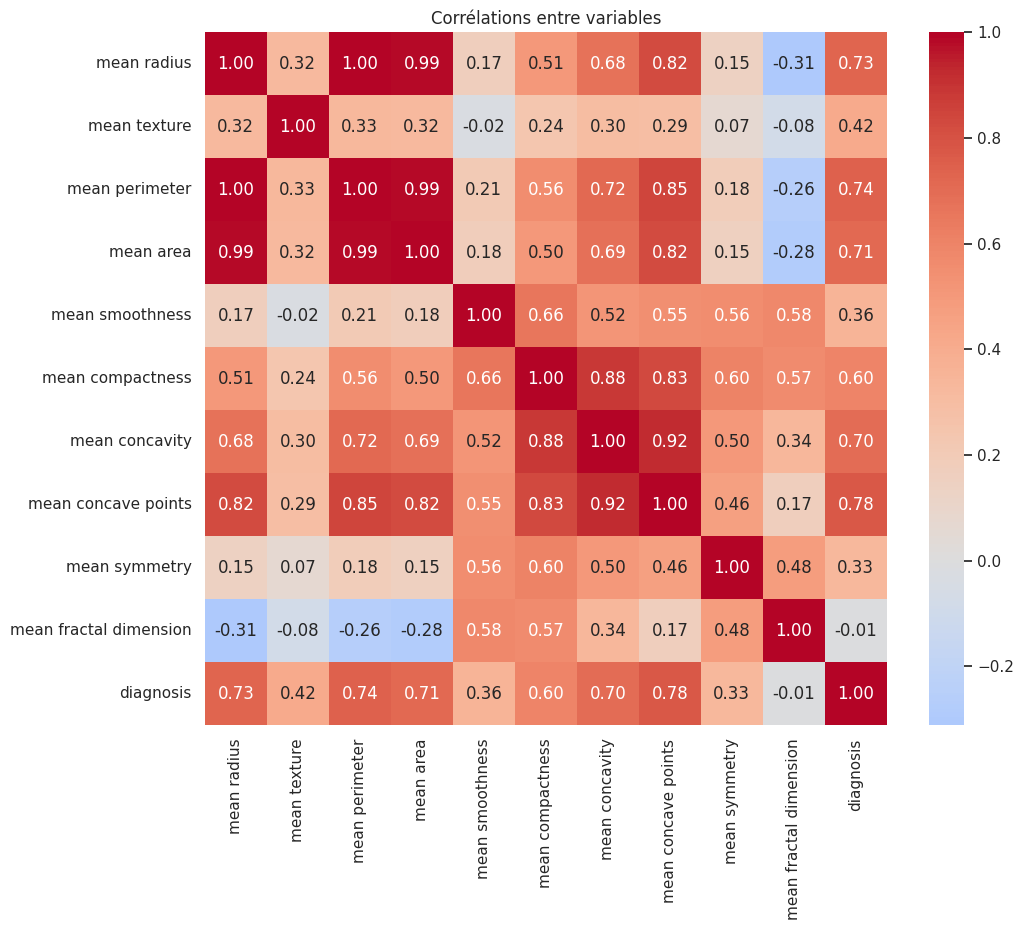

In [ ]:

mean_cols = [c for c in df.columns if c.startswith("mean")] + ["diagnosis"]
plt.figure(figsize=(11, 9))
sns.heatmap(df[mean_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations entre variables")
plt.show()


## 2. Préparation des données

In [ ]:
X = df.drop(columns="diagnosis")
y = df["diagnosis"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train :", X_train.shape, "| Test :", X_test.shape)
print(f"Cas malins — train : {y_train.mean():.1%} | test : {y_test.mean():.1%}")


Train : (455, 30) | Test : (114, 30)
Cas malins — train : 37.4% | test : 36.8%


## 3. Comparaison des modèles (validation croisée à 5 plis)

La **validation croisée** donne une estimation plus fiable qu'un seul split : chaque modèle est entraîné et évalué 5 fois sur des parties différentes du train.

In [ ]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(probability=True, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("clf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)),
    ]),
    "XGBoost": Pipeline([
        ("clf", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                              eval_metric="logloss", random_state=RANDOM_STATE)),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

results = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {m: scores[f"test_{m}"].mean() for m in scoring}

results_df = pd.DataFrame(results).T.sort_values("f1", ascending=False)
results_df.round(4)

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.9736,0.9771,0.9529,0.9640,0.9958
XGBoost,0.9714,0.9704,0.9529,0.9614,0.9924
SVM,0.9714,0.9769,0.9471,0.9610,0.9949
Random Forest,0.9604,0.9584,0.9353,0.9461,0.9880


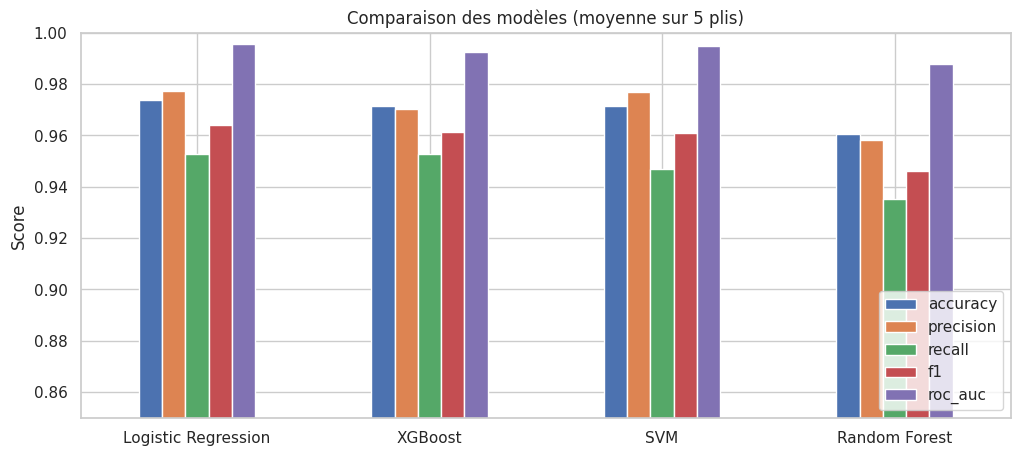

In [ ]:
results_df.plot(kind="bar", figsize=(12, 5), rot=0, ylim=(0.85, 1.0))
plt.title("Comparaison des modèles (moyenne sur 5 plis)")
plt.ylabel("Score"); plt.legend(loc="lower right")
plt.show()

## 4. Optimisation des hyperparamètres

On optimise le meilleur modèle (selon le F1) avec `GridSearchCV`. Le F1 équilibre precision et recall.

In [ ]:
param_grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10, 100], "clf__penalty": ["l2"]},
    "SVM": {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.001], "clf__kernel": ["rbf", "linear"]},
    "Random Forest": {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 5, 10],
                      "clf__min_samples_leaf": [1, 2, 4]},
    "XGBoost": {"clf__max_depth": [3, 4, 6], "clf__learning_rate": [0.03, 0.1],
                "clf__n_estimators": [200, 400]},
}

best_name = results_df.index[0]
print("Meilleur modèle en validation croisée :", best_name)

grid = GridSearchCV(models[best_name], param_grids[best_name], cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

print("Meilleurs hyperparamètres :", grid.best_params_)
print(f"F1 en validation croisée : {grid.best_score_:.4f}")
best_model = grid.best_estimator_

Meilleur modèle en validation croisée : Logistic Regression
Meilleurs hyperparamètres : {'clf__C': 1, 'clf__penalty': 'l2'}
F1 en validation croisée : 0.9640


## 5. Évaluation finale sur le jeu de test

In [ ]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(f"Modèle final : {best_name}\n")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}   (parmi les cas prédits malins, % réellement malins)")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}   (parmi les vrais cas malins, % détectés)")
print(f"F1-score  : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_proba):.4f}")
print("\n", classification_report(y_test, y_pred, target_names=["Bénin", "Malin"], digits=4))

Modèle final : Logistic Regression

Accuracy  : 0.9649
Precision : 0.9750   (parmi les cas prédits malins, % réellement malins)
Recall    : 0.9286   (parmi les vrais cas malins, % détectés)
F1-score  : 0.9512
ROC-AUC   : 0.9960

               precision    recall  f1-score   support

       Bénin     0.9595    0.9861    0.9726        72
       Malin     0.9750    0.9286    0.9512        42

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114



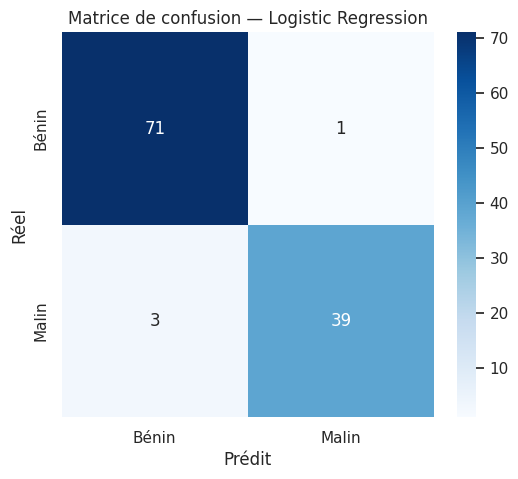

Faux négatifs (cancers non détectés) : 3
Faux positifs (fausses alertes)      : 1


In [ ]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Bénin", "Malin"], yticklabels=["Bénin", "Malin"])
plt.title(f"Matrice de confusion — {best_name}")
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Faux négatifs (cancers non détectés) : {fn}")
print(f"Faux positifs (fausses alertes)      : {fp}")

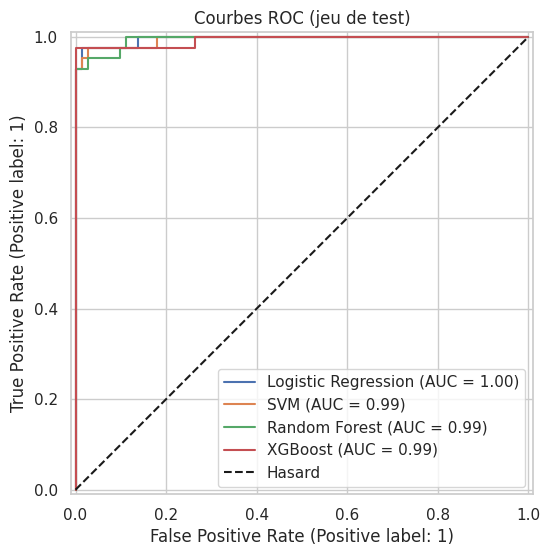

In [ ]:

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    model.fit(X_train, y_train)
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Hasard")
ax.set_title("Courbes ROC (jeu de test)")
ax.legend(loc="lower right")
plt.show()

### Ajuster le seuil de décision (optionnel mais apprécié)

Par défaut, une patiente est classée « maligne » si la probabilité dépasse 0,5. **Abaisser ce seuil** permet de détecter plus de cancers (meilleur recall), au prix de quelques fausses alertes de plus. C'est souvent le bon compromis en médecine.

In [ ]:
for threshold in [0.5, 0.4, 0.3, 0.2]:
    pred_t = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
    print(f"Seuil {threshold:.1f} -> recall {recall_score(y_test, pred_t):.3f} | "
          f"precision {precision_score(y_test, pred_t):.3f} | "
          f"cancers ratés : {fn} | fausses alertes : {fp}")

Seuil 0.5 -> recall 0.929 | precision 0.975 | cancers ratés : 3 | fausses alertes : 1
Seuil 0.4 -> recall 0.952 | precision 0.976 | cancers ratés : 2 | fausses alertes : 1
Seuil 0.3 -> recall 0.976 | precision 0.976 | cancers ratés : 1 | fausses alertes : 1
Seuil 0.2 -> recall 0.976 | precision 0.911 | cancers ratés : 1 | fausses alertes : 4


## 6. Importance des variables

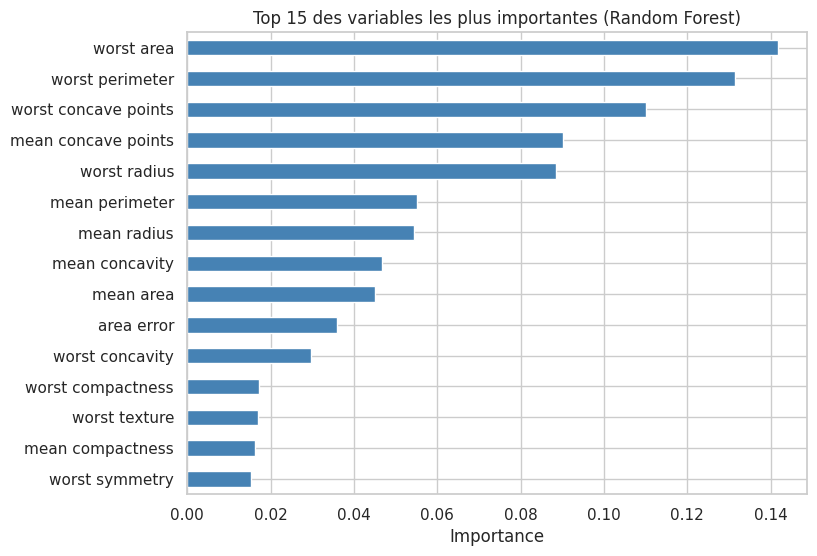

In [ ]:

rf = RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE).fit(X_train, y_train)
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
importances.head(15).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 15 des variables les plus importantes (Random Forest)")
plt.xlabel("Importance")
plt.show()


## 7. Sauvegarde du modèle et prédiction sur un nouveau patient

In [ ]:
joblib.dump(best_model, "disease_prediction_model.joblib")
print("Modèle sauvegardé : disease_prediction_model.joblib")


Modèle sauvegardé : disease_prediction_model.joblib


In [ ]:
def predict_patient(model, patient: pd.DataFrame, threshold: float = 0.5):
    """Renvoie le diagnostic prédit et la probabilité de malignité."""
    proba = model.predict_proba(patient)[0, 1]
    label = "MALIN " if proba >= threshold else "BÉNIN "
    return label, proba

loaded = joblib.load("disease_prediction_model.joblib")
for i in range(3):
    patient = X_test.iloc[[i]]
    label, proba = predict_patient(loaded, patient)
    real = "MALIN" if y_test.iloc[i] == 1 else "BÉNIN"
    print(f"Patiente {i+1} -> prédiction : {label} (proba {proba:.1%}) | réel : {real}")

Patiente 1 -> prédiction : BÉNIN  (proba 0.0%) | réel : BÉNIN
Patiente 2 -> prédiction : MALIN  (proba 100.0%) | réel : MALIN
Patiente 3 -> prédiction : BÉNIN  (proba 4.3%) | réel : BÉNIN


##  Conclusion

- Les 4 modèles dépassent **95 % d'accuracy**. Les modèles linéaires (Logistic Regression, SVM) avec standardisation sont les plus performants sur ce dataset.
- Le modèle final atteint **96,5 % d'accuracy** et un **ROC-AUC de 0,996** sur le jeu de test.
- Les variables les plus prédictives décrivent la **taille** et l'**irrégularité** de la tumeur.
- Ajuster le **seuil de décision** permet de réduire les cancers non détectés, ce qui est prioritaire en contexte médical : au seuil 0,3, un seul cancer sur 42 est manqué (contre 3 au seuil 0,5).
